# Power Spectra Tutorial

This notebook demonstrates estimating various power spectra using `tools21cm`. We cover:

1. **Test fields** — Gaussian random field and a bubble (reionization-like) field, with known analytical power spectra  
2. **1D Power spectrum** — 1D spherically averaged P(k) and validation via the N-point polyspectrum estimator  
3. **2D Power spectrum** — 2D cylindrical P(k⊥, k∥) with foreground wedge  
4. **Cross power spectrum** — cross-correlation between two fields  
5. **Line-of-sight anisotropy**  
   - P(k, μ)  
   - Anisotropy ratio r_μ(k)  

Analytical solutions from [Bharadwaj & Pandey 2005](https://academic.oup.com/mnras/article/358/3/968/1028528) are overlaid on each plot for the bubble field.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tools21cm as t2c
from scipy.special import spherical_jn

print('tools21cm version:', t2c.__version__)


tools21cm version: 2.4.1


## 1. Test fields

We work with two physically motivated 3D fields:

- **GRF** — Gaussian random field with a power-law spectrum P(k) ∝ k⁻³. All odd-point functions vanish exactly.
- **Bubble field** — a neutral background with Poisson-distributed identical spherical ionized regions. This has a well-defined analytical power spectrum ([Bharadwaj & Pandey 2005](https://academic.oup.com/mnras/article/358/3/968/1028528)), making it an ideal test case.

For Poisson-distributed identical spheres of radius R the power spectrum is:

$$P(k) = \bar{n}\, V_b^2\, W^2(kR)$$

where $\bar{n} = N_b/V$ is the bubble number density, $V_b = \tfrac{4\pi}{3}R^3$, and

$$W(x) = \frac{3j_1(x)}{x} = \frac{3[\sin x - x\cos x]}{x^3}$$

is the normalised Fourier transform of a uniform sphere ($W \to 1$ as $x \to 0$).

In [2]:
# Box parameters
N       = 128      # grid cells per side
box_Mpc = 200.0    # comoving box size [Mpc]

# --- Gaussian random field ---
d_grf = t2c.make_gaussian_random_field(
    power_spectrum=lambda k: k**-3,
    dims=(N, N, N), box_dims=box_Mpc, random_seed=42
)

# --- Bubble field ---
# Poisson-distributed identical spherical bubbles (ionized inside, neutral outside)
# Analytical power- and bi-spectrum known; see Bharadwaj & Pandey 2005
np.random.seed(7)
n_bubbles = 80
R_Mpc     = 8.0                        # bubble radius [Mpc]
R_cells   = R_Mpc / (box_Mpc / N)      # bubble radius [cells]

d_bubble = np.ones((N, N, N), dtype='float64')
xi, yi, zi = np.indices((N, N, N))
for _ in range(n_bubbles):
    cx, cy, cz = np.random.randint(0, N, 3)
    dx = np.minimum(np.abs(xi - cx), N - np.abs(xi - cx))
    dy = np.minimum(np.abs(yi - cy), N - np.abs(yi - cy))
    dz = np.minimum(np.abs(zi - cz), N - np.abs(zi - cz))
    d_bubble[np.sqrt(dx**2 + dy**2 + dz**2) < R_cells] = 0.0
d_bubble -= d_bubble.mean()   # zero-mean contrast field

print(f'GRF shape: {d_grf.shape}  |  box: {box_Mpc} Mpc')
print(f'Bubble field: {n_bubbles} bubbles, R = {R_Mpc} Mpc, '
      f'ionised fraction = {(d_bubble < 0).mean():.2f}')

GRF shape: (128, 128, 128)  |  box: 200.0 Mpc
Bubble field: 80 bubbles, R = 8.0 Mpc, ionised fraction = 0.02


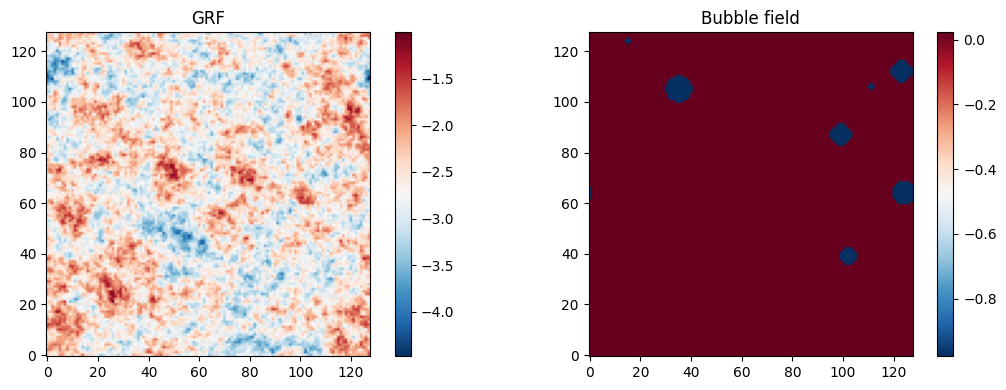

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, title in zip(axes, [d_grf, d_bubble], ['GRF', 'Bubble field']):
    im = ax.imshow(d[:, :, N // 2], origin='lower', cmap='RdBu_r')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### 1b. Analytical helpers and k limits

We define the sphere window function and k-limits used throughout:

| `k_limit` | value |
|---|---|
| `'nyquist'` | $k_{\rm Ny} = \pi N / L$ |
| `'aliasing'` | $k_{\rm Ny}/2$ (more conservative) |
| `None` | $k_{\rm max}$ from the grid corner ($\sqrt{3}\,k_{\rm Ny}$) |

In [4]:
from scipy.special import spherical_jn

# --- k limits ---
k_fundamental = 2 * np.pi / box_Mpc
k_nyquist     = np.pi * N / box_Mpc       # pi / dx
k_aliasing    = k_nyquist / 2              # 1/2 of Nyquist (more conservative)

k_limit = 'nyquist'   # choose: None, 'nyquist', 'aliasing'
kmax = {'nyquist': k_nyquist, 'aliasing': k_aliasing}.get(k_limit)

print(f'k_fundamental = {k_fundamental:.4f} Mpc⁻¹')
print(f'k_nyquist     = {k_nyquist:.4f} Mpc⁻¹')
print(f'k_aliasing    = {k_aliasing:.4f} Mpc⁻¹')
if kmax:
    print(f'k_limit = {k_limit!r}  →  kmax = {kmax:.4f} Mpc⁻¹')
else:
    print('k_limit = None  →  kmax = grid corner (default)')

# --- Bubble field analytical polyspectra ---
n_b = n_bubbles / box_Mpc**3       # number density [Mpc⁻³]
V_b = (4/3) * np.pi * R_Mpc**3    # single bubble volume [Mpc³]

def W_sphere(x):
    """Normalised FT of a uniform sphere: 3j1(x)/x, limit 1 as x->0."""
    return np.where(np.abs(x) < 1e-6, 1.0, 3 * spherical_jn(1, x) / x)

def P_bubble_analytic(k):
    """Bharadwaj & Pandey 2005: P(k) for Poisson-distributed identical spheres."""
    return n_b * V_b**2 * W_sphere(k * R_Mpc)**2

def B_bubble_analytic(k):
    """Bharadwaj & Pandey 2005: equilateral B(k,k,k) for Poisson-distributed identical spheres."""
    return n_b * V_b**3 * W_sphere(k * R_Mpc)**3

k_fundamental = 0.0314 Mpc⁻¹
k_nyquist     = 2.0106 Mpc⁻¹
k_aliasing    = 1.0053 Mpc⁻¹
k_limit = 'nyquist'  →  kmax = 2.0106 Mpc⁻¹


## 2. 1D Power spectrum - Spherically averaged P(k)

`power_spectrum_1d` internally calls `power_spectrum_nd` (raw 3D FFT power) and radially averages over shells of constant |k|. The dimensionless variant Δ²(k) = k³ P(k) / (2π²) follows directly.

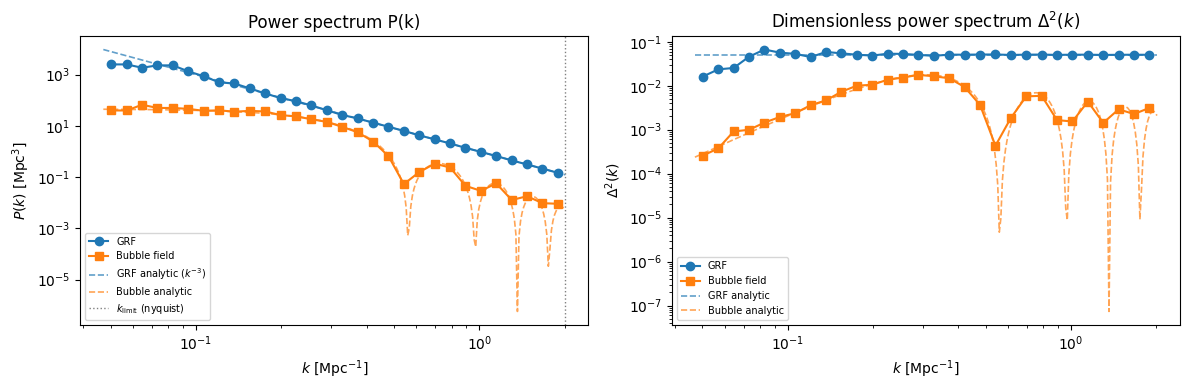

In [13]:
n_kbins_1d = 30
kmin_1d    = k_fundamental * 1.5
kmax_1d    = kmax if kmax is not None else k_nyquist
kbins_1d   = np.geomspace(kmin_1d, kmax_1d, n_kbins_1d + 1)

Pk_grf,    ks = t2c.power_spectrum_1d(d_grf,    kbins=kbins_1d, box_dims=box_Mpc)
Pk_bubble, _  = t2c.power_spectrum_1d(d_bubble, kbins=kbins_1d, box_dims=box_Mpc)

# Fitted normalization for GRF analytical curve
C_grf  = np.median(Pk_grf * ks**3)
k_plot = np.geomspace(kbins_1d[0], kbins_1d[-1], 300)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- P(k) ---
axes[0].loglog(ks, Pk_grf,    'o-', lw=1.5, label='GRF')
axes[0].loglog(ks, Pk_bubble, 's-', lw=1.5, label='Bubble field')
axes[0].loglog(k_plot, C_grf * k_plot**(-3),       '--', lw=1.2, color='C0', alpha=0.7, label=r'GRF analytic ($k^{-3}$)')
axes[0].loglog(k_plot, P_bubble_analytic(k_plot),   '--', lw=1.2, color='C1', alpha=0.7, label='Bubble analytic')
axes[0].axvline(kmax_1d, color='gray', ls=':', lw=1, label=f'$k_{{\\rm limit}}$ ({k_limit})')
axes[0].set_xlabel(r'$k$ [Mpc$^{-1}$]')
axes[0].set_ylabel(r'$P(k)$ [Mpc$^3$]')
axes[0].set_title('Power spectrum P(k)')
axes[0].legend(fontsize=7)

# --- Δ²(k) = k³P(k)/(2π²) ---
D2_grf    = ks**3 * Pk_grf    / (2 * np.pi**2)
D2_bubble = ks**3 * Pk_bubble / (2 * np.pi**2)
axes[1].loglog(ks, D2_grf,    'o-', lw=1.5, label='GRF')
axes[1].loglog(ks, D2_bubble, 's-', lw=1.5, label='Bubble field')
axes[1].loglog(k_plot, k_plot**3 * C_grf * k_plot**(-3) / (2*np.pi**2), '--', lw=1.2, color='C0', alpha=0.7, label=r'GRF analytic')
axes[1].loglog(k_plot, k_plot**3 * P_bubble_analytic(k_plot) / (2*np.pi**2), '--', lw=1.2, color='C1', alpha=0.7, label='Bubble analytic')
axes[1].set_xlabel(r'$k$ [Mpc$^{-1}$]')
axes[1].set_ylabel(r'$\Delta^2(k)$')
axes[1].set_title(r'Dimensionless power spectrum $\Delta^2(k)$')
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

## 3. 2D Power spectrum

### 3a. Cylindrical P(k⊥, k∥)

`power_spectrum_2d` splits modes into perpendicular (k⊥) and line-of-sight (k∥) components. Standard for foreground separation studies. `nu_axis` sets the LoS array axis.

In [6]:
Pk2d, kper, kpar = t2c.power_spectrum_2d(
    d_grf, kbins=10, box_dims=box_Mpc, binning='log', nu_axis=2
)
print('Pk2d shape:', Pk2d.shape)

Pk2d shape: (10, 10)


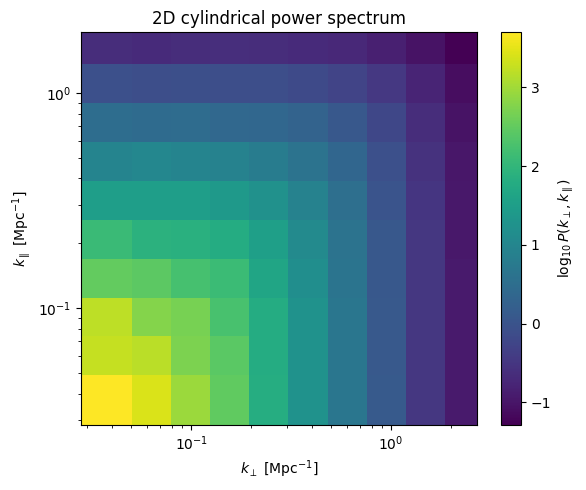

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
pcm = ax.pcolormesh(kper, kpar, np.log10(np.abs(Pk2d.T) + 1e-30),
                    cmap='viridis', shading='auto')
plt.colorbar(pcm, ax=ax, label=r'$\log_{10} P(k_\perp, k_\parallel)$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$k_\perp$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$k_\parallel$ [Mpc$^{-1}$]')
ax.set_title('2D cylindrical power spectrum')
plt.tight_layout()
plt.show()

### 3b. Foreground wedge

Foreground contamination from spectrally smooth sources occupies a wedge-shaped region in the (k⊥, k∥) plane. `plot_2d_power` overlays it automatically.

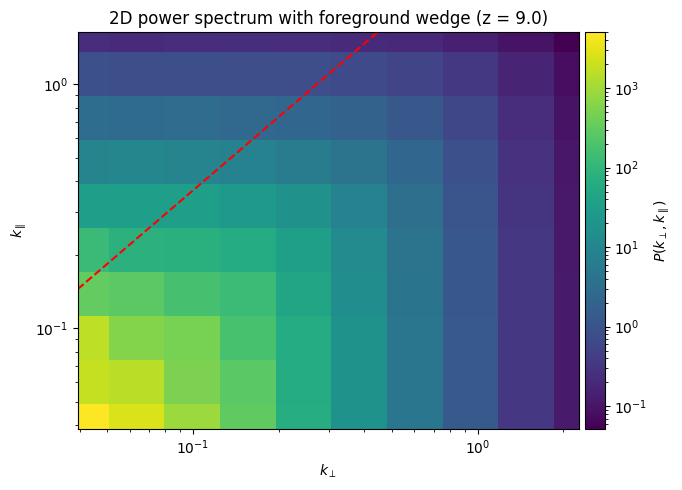

In [8]:
z_obs = 9.0

fig = t2c.plot_2d_power(
    ps=(Pk2d, kper, kpar),
    draw_wedge={'z': z_obs, 'fov_deg': 90.0, 'ls': '--', 'color': 'r'},
    cmap='viridis'
)
fig.axes[0].set_title(f'2D power spectrum with foreground wedge (z = {z_obs})')
plt.tight_layout()
plt.show()

## 4. Cross power spectrum

`cross_power_spectrum_1d` estimates the cross-power between two fields. Cross-correlating the GRF with the bubble field probes the correlation structure between a Gaussian signal and a non-Gaussian, topology-driven one.

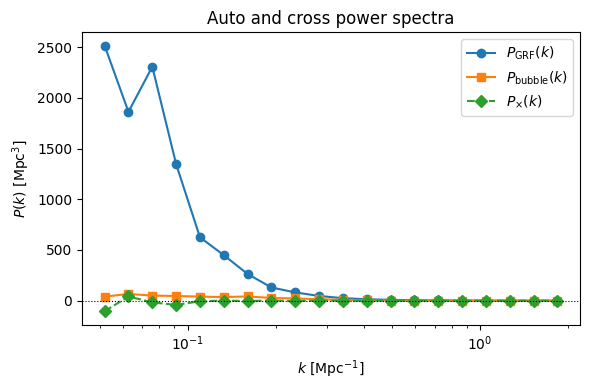

In [9]:
Pk_cross, ks_cross = t2c.cross_power_spectrum_1d(
    d_grf, d_bubble, kbins=kbins_1d, box_dims=box_Mpc
)

plt.figure(figsize=(6, 4))
plt.semilogx(ks,       Pk_grf,    'o-',  lw=1.5, label=r'$P_{\rm GRF}(k)$')
plt.semilogx(ks,       Pk_bubble, 's-',  lw=1.5, label=r'$P_{\rm bubble}(k)$')
plt.semilogx(ks_cross, Pk_cross,  'D--', lw=1.5, label=r'$P_{\times}(k)$')
plt.axhline(0, color='k', lw=0.8, ls=':')
plt.xlabel(r'$k$ [Mpc$^{-1}$]')
plt.ylabel(r'$P(k)$ [Mpc$^3$]')
plt.title('Auto and cross power spectra')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Line-of-sight anisotropy

### 5a. P(k, μ)

`power_spectrum_mu` bins modes in both k and μ = cos θ (angle to LoS). Anisotropies from redshift-space distortions or the light-cone effect appear as μ-dependent structure.

P(k,mu) shape (n_mu x n_k): (10, 15)


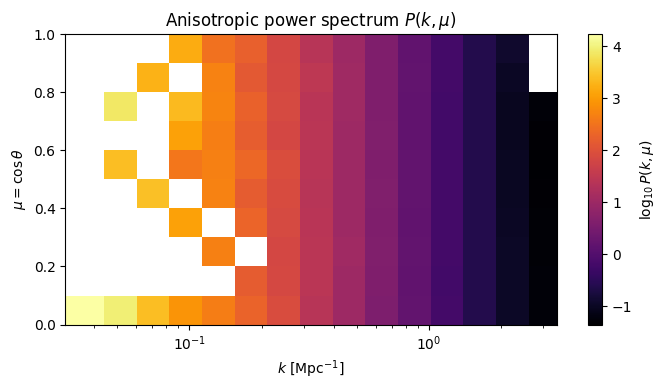

In [10]:
Pk_mu, mubins, kbins_mu = t2c.power_spectrum_mu(
    d_grf, los_axis=2, mubins=10, kbins=15, box_dims=box_Mpc
)
print('P(k,mu) shape (n_mu x n_k):', Pk_mu.shape)

fig, ax = plt.subplots(figsize=(7, 4))
pcm = ax.pcolormesh(kbins_mu, mubins, np.log10(np.abs(Pk_mu) + 1e-30),
                    cmap='inferno', shading='auto')
plt.colorbar(pcm, ax=ax, label=r'$\log_{10} P(k,\mu)$')
ax.set_xscale('log')
ax.set_xlabel(r'$k$ [Mpc$^{-1}$]')
ax.set_ylabel(r'$\mu = \cos\theta$')
ax.set_title(r'Anisotropic power spectrum $P(k,\mu)$')
plt.tight_layout()
plt.show()

### 5b. Anisotropy ratio $r_μ(k)$

`anisotropy_ratio_r_mu` measures the power asymmetry between high-μ (LoS-dominated) and low-μ (transverse) modes. For a purely isotropic field this is zero; non-zero values signal redshift-space distortions or light-cone effects.

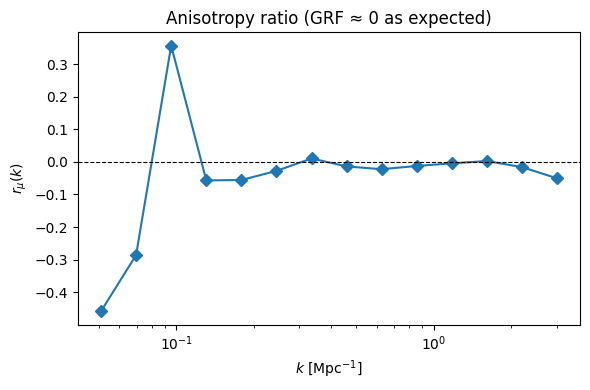

In [11]:
rmu, k_rmu = t2c.anisotropy_ratio_r_mu(
    d_grf, los_axis=2, mu_cut=0.5, mubins=20, kbins=15, box_dims=box_Mpc
)

plt.figure(figsize=(6, 4))
plt.semilogx(k_rmu, rmu, 'D-', lw=1.5)
plt.axhline(0, color='k', lw=0.8, ls='--')
plt.xlabel(r'$k$ [Mpc$^{-1}$]')
plt.ylabel(r'$r_\mu(k)$')
plt.title('Anisotropy ratio (GRF ≈ 0 as expected)')
plt.tight_layout()
plt.show()

## Summary

| Statistic | Function | Output |
|-----------|----------|--------|
| 1D power spectrum | `power_spectrum_1d` | P(k) |
| Dimensionless power | k³P(k)/(2π²) inline | Δ²(k) |
| 2D cylindrical | `power_spectrum_2d` | P(k⊥, k∥) |
| Foreground wedge | `plot_2d_power` | wedge overlay |
| Cross power | `cross_power_spectrum_1d` | P×(k) |
| P(k, μ) | `power_spectrum_mu` | P(k, μ) |
| Anisotropy ratio | `anisotropy_ratio_r_mu` | rμ(k) |